# Weather Data

## Data Source

This dataset is a potential source of external information to integrate into our project. The data was obtained from the [Open-Meteo Historical Forecast API](https://open-meteo.com/en/docs/gfs-api?timezone=America%2FChicago&latitude=41.85&longitude=-87.65&time_mode=time_interval&start_date=2026-01-01&end_date=2026-10-21&api_mode=historical_forecast&hourly=&minutely_15=rain,temperature_2m,snowfall,sunshine_duration,weather_code,is_day&daily=weather_code), using weather data for Chicago.

## Data description

- time
- weather_code (wmo code)
- temperature_2m_max (°C)
- temperature_2m_min (°C)
- rain_sum (mm)
- snowfall_sum (cm)
- showers_sum (mm)
- wind_speed_10m_max (km/h)
- precipitation_sum (mm)
- sunrise (iso8601)
- sunset (iso8601)
- daylight_duration (s)

## Objective

The objective of this preliminary analysis is to characterize the dataset, assess the variability and relevance of the available meteorological variables.

In [1]:
# Import libraries
import pandas as pd
import numpy as np
from collections import Counter
import matplotlib.pyplot as plt

In [178]:
# Reading files
data_folder = './raw/'
weather22 = pd.read_csv(data_folder + 'weather_2022.csv', skiprows=3)
weather23 = pd.read_csv(data_folder + 'weather_2023.csv', skiprows=3)
weather24 = pd.read_csv(data_folder + 'weather_2024.csv', skiprows=3)
weather25 = pd.read_csv(data_folder + 'weather_2025.csv', skiprows=3)

### Sanity checks:

In [179]:
# Sanity check: print the shape of the dataframes
# We have yearly reports, so we expect 365 rows
print(f'For 2022 we have reports from: {weather22.shape[0]} days')
print(f'For 2023 we have reports from: {weather23.shape[0]} days')
print(f'For 2024 we have reports from: {weather24.shape[0]} days')
print(f'For 2025 we have reports from: {weather25.shape[0]} days')

For 2022 we have reports from: 365 days
For 2023 we have reports from: 365 days
For 2024 we have reports from: 366 days
For 2025 we have reports from: 365 days


In [180]:
# Do we have NA values?
print(f'For 2022 we have: NA values:\n{weather22.isna().sum()}\n')
print(f'For 2023 we have: NA values:\n{weather23.isna().sum()}\n')
print(f'For 2024 we have: NA values:\n{weather24.isna().sum()}\n')
print(f'For 2025 we have: NA values:\n{weather25.isna().sum()}\n')

For 2022 we have: NA values:
time                         0
weather_code (wmo code)      0
temperature_2m_max (°C)      0
temperature_2m_min (°C)      0
sunrise (iso8601)            0
sunset (iso8601)             0
rain_sum (mm)                0
showers_sum (mm)             0
snowfall_sum (cm)            0
wind_speed_10m_max (km/h)    0
precipitation_sum (mm)       0
daylight_duration (s)        0
dtype: int64

For 2023 we have: NA values:
time                         0
weather_code (wmo code)      0
temperature_2m_max (°C)      0
temperature_2m_min (°C)      0
sunrise (iso8601)            0
sunset (iso8601)             0
rain_sum (mm)                0
showers_sum (mm)             0
snowfall_sum (cm)            0
wind_speed_10m_max (km/h)    0
precipitation_sum (mm)       0
daylight_duration (s)        0
dtype: int64

For 2024 we have: NA values:
time                         0
weather_code (wmo code)      0
temperature_2m_max (°C)      0
temperature_2m_min (°C)      0
sunrise (iso8601)

### Data exploration:

In [181]:
# Print columns 
weather22.columns

Index(['time', 'weather_code (wmo code)', 'temperature_2m_max (°C)',
       'temperature_2m_min (°C)', 'sunrise (iso8601)', 'sunset (iso8601)',
       'rain_sum (mm)', 'showers_sum (mm)', 'snowfall_sum (cm)',
       'wind_speed_10m_max (km/h)', 'precipitation_sum (mm)',
       'daylight_duration (s)'],
      dtype='str')

In [182]:
# Rename columns:
new_names ={'weather_code (wmo code)':'weather_code',
            'sunrise (iso8601)':'sunrise',
            'daylight_duration (s)':'daylight_duration',
            'temperature_2m_max (°C)':'temperature_2m_max',
            'temperature_2m_min (°C)':'temperature_2m_min',
            'sunset (iso8601)':'sunset',
            'rain_sum (mm)':'rain_sum',
            'snowfall_sum (cm)':'snowfall_sum',
            'wind_speed_10m_max (km/h)': 'wind_speed_10m_max',
            'showers_sum (mm)': 'showers_sum',
            'precipitation_sum (mm)': 'precipitation_sum'
                              }

In [183]:
weather22 = weather22.rename(columns= new_names)
weather23 = weather23.rename(columns= new_names)
weather24 = weather24.rename(columns= new_names)
weather25 = weather25.rename(columns= new_names)

In [184]:
weather22

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,showers_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration
0,01/01/2022,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,0,5.32,36.6,11.2,33123.81
1,02/01/2022,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,0,4.34,34.4,8.8,33170.56
2,03/01/2022,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0,0.00,26.0,0.0,33221.36
3,04/01/2022,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0,0.00,24.6,0.0,33276.72
4,05/01/2022,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0,0.00,44.8,0.0,33336.53
...,...,...,...,...,...,...,...,...,...,...,...,...
360,27/12/2022,45,-4.0,-12.0,2022-12-27T08:17,2022-12-27T17:26,0.0,0,0.00,23.0,0.0,32936.50
361,28/12/2022,3,6.2,-4.0,2022-12-28T08:17,2022-12-28T17:27,0.0,0,0.00,25.9,0.0,32962.27
362,29/12/2022,3,13.3,5.7,2022-12-29T08:17,2022-12-29T17:27,0.0,0,0.00,24.7,0.0,32992.41
363,30/12/2022,3,13.3,0.3,2022-12-30T08:17,2022-12-30T17:28,0.0,0,0.00,24.0,0.0,33027.19


In [185]:
# Concatenate data in a single DF
weather22_25 = pd.concat([weather22, weather23, weather24, weather25], ignore_index=True)

In [187]:
# Incorporate weather code meaning 
weather_code = {
	"0": "Clear sky",
	"1": "Mainly clear",
	"2": "Partly cloudy",
	"3": "Overcast",
	"45": "Fog",
	"48": "Depositing rime fog",
	"51": "Light drizzle",
	"53": "Moderate drizzle",
	"55": "Dense drizzle",
	"56": "Light freezing drizzle",
	"57": "Dense freezing drizzle",
	"61": "Slight rain",
	"63": "Moderate rain",
	"65": "Heavy rain",
	"66": "Light freezing rain",
	"67": "Heavy freezing rain",
	"71": "Slight snowfall",
	"73": "Moderate snowfall",
	"75": "Heavy snowfall",
	"77": "Snow grains",
	"80": "Slight rain showers",
	"81": "Moderate rain showers",
	"82": "Violent rain showers",
	"85": "Slight snow showers",
	"86": "Heavy snow showers",
	"95": "Thunderstorm",
	"96": "Thunderstorm with slight hail",
	"97": "Heavy thunderstorm",
	"99": "Thunderstorm with heavy hail"
}

In [188]:
# Add weather code
weather22_25["weather"] = weather22_25["weather_code"].astype(str).map(weather_code)

In [189]:
# For data handling is best to have separate columns with month and year
weather22_25["month"] = [int(time.split("/")[1]) for time in weather22_25.time]
weather22_25["year"] = [int(time.split("/")[2]) for time in weather22_25.time]

In [190]:
weather22_25

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,showers_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather,month,year
0,01/01/2022,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,0,5.32,36.6,11.2,33123.81,Heavy snowfall,1,2022
1,02/01/2022,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,0,4.34,34.4,8.8,33170.56,Heavy snowfall,1,2022
2,03/01/2022,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0,0.00,26.0,0.0,33221.36,Mainly clear,1,2022
3,04/01/2022,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0,0.00,24.6,0.0,33276.72,Overcast,1,2022
4,05/01/2022,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0,0.00,44.8,0.0,33336.53,Overcast,1,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,27/12/2025,3,5.2,3.0,2025-12-27T08:17,2025-12-27T17:26,0.0,0,0.00,15.5,0.0,32948.73,Overcast,12,2025
1457,28/12/2025,63,14.0,-3.0,2025-12-28T08:17,2025-12-28T17:27,28.5,0,0.00,36.5,28.5,32975.78,Moderate rain,12,2025
1458,29/12/2025,73,-3.0,-9.8,2025-12-29T08:17,2025-12-29T17:28,0.4,0,0.84,39.4,1.6,33006.84,Moderate snowfall,12,2025
1459,30/12/2025,73,-4.6,-11.6,2025-12-30T08:18,2025-12-30T17:28,0.4,0,0.70,17.1,1.4,33041.90,Moderate snowfall,12,2025


In [191]:
weather22_25["time"] = pd.to_datetime(
    weather22_25["time"],
    format="%d/%m/%Y"
)
weather22_25["time"] = weather22_25["time"].dt.strftime("%Y-%m-%d")

In [192]:
weather22_25

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,showers_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather,month,year
0,2022-01-01,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,0,5.32,36.6,11.2,33123.81,Heavy snowfall,1,2022
1,2022-01-02,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,0,4.34,34.4,8.8,33170.56,Heavy snowfall,1,2022
2,2022-01-03,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0,0.00,26.0,0.0,33221.36,Mainly clear,1,2022
3,2022-01-04,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0,0.00,24.6,0.0,33276.72,Overcast,1,2022
4,2022-01-05,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0,0.00,44.8,0.0,33336.53,Overcast,1,2022
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,2025-12-27,3,5.2,3.0,2025-12-27T08:17,2025-12-27T17:26,0.0,0,0.00,15.5,0.0,32948.73,Overcast,12,2025
1457,2025-12-28,63,14.0,-3.0,2025-12-28T08:17,2025-12-28T17:27,28.5,0,0.00,36.5,28.5,32975.78,Moderate rain,12,2025
1458,2025-12-29,73,-3.0,-9.8,2025-12-29T08:17,2025-12-29T17:28,0.4,0,0.84,39.4,1.6,33006.84,Moderate snowfall,12,2025
1459,2025-12-30,73,-4.6,-11.6,2025-12-30T08:18,2025-12-30T17:28,0.4,0,0.70,17.1,1.4,33041.90,Moderate snowfall,12,2025


In [193]:
# We just have max and min temperature per day, so we can get the mean temperature per day as the average of the two (maybe more informative)
# Since lowest temperature is usually at night and highest during the day, the mean temperature is a good approximation of the average temperature during the day.
# Standard Practice: Meteorologists and weather stations commonly use this method because it is simple and works well for long-term climate tracking and historical records.
# Accuracy Limitation: This method assumes a smooth, symmetrical daily temperature curve. In reality, a more precise daily mean requires averaging hourly (or continuous) temperature readings over the 24-hour period, as temperatures do not always spend equal time at high and low extremes
# https://climate.rutgers.edu/stateclim/?section=menu&%20target=calculating_daily_mean_temperature

weather22_25["temperature_mean"] = (weather22_25["temperature_2m_max"] + weather22_25["temperature_2m_min"]) / 2

In [194]:
weather22_25

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,showers_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather,month,year,temperature_mean
0,2022-01-01,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,0,5.32,36.6,11.2,33123.81,Heavy snowfall,1,2022,0.85
1,2022-01-02,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,0,4.34,34.4,8.8,33170.56,Heavy snowfall,1,2022,-5.55
2,2022-01-03,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0,0.00,26.0,0.0,33221.36,Mainly clear,1,2022,-9.15
3,2022-01-04,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0,0.00,24.6,0.0,33276.72,Overcast,1,2022,-3.15
4,2022-01-05,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0,0.00,44.8,0.0,33336.53,Overcast,1,2022,-6.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,2025-12-27,3,5.2,3.0,2025-12-27T08:17,2025-12-27T17:26,0.0,0,0.00,15.5,0.0,32948.73,Overcast,12,2025,4.10
1457,2025-12-28,63,14.0,-3.0,2025-12-28T08:17,2025-12-28T17:27,28.5,0,0.00,36.5,28.5,32975.78,Moderate rain,12,2025,5.50
1458,2025-12-29,73,-3.0,-9.8,2025-12-29T08:17,2025-12-29T17:28,0.4,0,0.84,39.4,1.6,33006.84,Moderate snowfall,12,2025,-6.40
1459,2025-12-30,73,-4.6,-11.6,2025-12-30T08:18,2025-12-30T17:28,0.4,0,0.70,17.1,1.4,33041.90,Moderate snowfall,12,2025,-8.10


In [195]:
# Shower_sum variable not well documented: Non informative: all 0 values
weather22_25.showers_sum.describe

<bound method NDFrame.describe of 0       0
1       0
2       0
3       0
4       0
       ..
1456    0
1457    0
1458    0
1459    0
1460    0
Name: showers_sum, Length: 1461, dtype: int64>

In [197]:
weather22_25 = weather22_25.drop(columns=["showers_sum"])

In [198]:
weather22_25

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather,month,year,temperature_mean
0,2022-01-01,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,5.32,36.6,11.2,33123.81,Heavy snowfall,1,2022,0.85
1,2022-01-02,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,4.34,34.4,8.8,33170.56,Heavy snowfall,1,2022,-5.55
2,2022-01-03,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0.00,26.0,0.0,33221.36,Mainly clear,1,2022,-9.15
3,2022-01-04,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0.00,24.6,0.0,33276.72,Overcast,1,2022,-3.15
4,2022-01-05,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0.00,44.8,0.0,33336.53,Overcast,1,2022,-6.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,2025-12-27,3,5.2,3.0,2025-12-27T08:17,2025-12-27T17:26,0.0,0.00,15.5,0.0,32948.73,Overcast,12,2025,4.10
1457,2025-12-28,63,14.0,-3.0,2025-12-28T08:17,2025-12-28T17:27,28.5,0.00,36.5,28.5,32975.78,Moderate rain,12,2025,5.50
1458,2025-12-29,73,-3.0,-9.8,2025-12-29T08:17,2025-12-29T17:28,0.4,0.84,39.4,1.6,33006.84,Moderate snowfall,12,2025,-6.40
1459,2025-12-30,73,-4.6,-11.6,2025-12-30T08:18,2025-12-30T17:28,0.4,0.70,17.1,1.4,33041.90,Moderate snowfall,12,2025,-8.10


In [199]:
# Save data as one single file
save_folder = './clean/'
weather22_25.to_csv(save_folder + "weather_2022_2025.csv", index=False)

# Exploratory analysis

In [200]:
# Importing libraries for plotting
import matplotlib.pyplot as plt
import seaborn as sns

In [201]:
# Reading files
save_folder = './clean/'
weather22_25 = pd.read_csv(save_folder + 'weather_2022_2025.csv')

In [202]:
weather22_25

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather,month,year,temperature_mean
0,2022-01-01,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,5.32,36.6,11.2,33123.81,Heavy snowfall,1,2022,0.85
1,2022-01-02,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,4.34,34.4,8.8,33170.56,Heavy snowfall,1,2022,-5.55
2,2022-01-03,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0.00,26.0,0.0,33221.36,Mainly clear,1,2022,-9.15
3,2022-01-04,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0.00,24.6,0.0,33276.72,Overcast,1,2022,-3.15
4,2022-01-05,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0.00,44.8,0.0,33336.53,Overcast,1,2022,-6.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,2025-12-27,3,5.2,3.0,2025-12-27T08:17,2025-12-27T17:26,0.0,0.00,15.5,0.0,32948.73,Overcast,12,2025,4.10
1457,2025-12-28,63,14.0,-3.0,2025-12-28T08:17,2025-12-28T17:27,28.5,0.00,36.5,28.5,32975.78,Moderate rain,12,2025,5.50
1458,2025-12-29,73,-3.0,-9.8,2025-12-29T08:17,2025-12-29T17:28,0.4,0.84,39.4,1.6,33006.84,Moderate snowfall,12,2025,-6.40
1459,2025-12-30,73,-4.6,-11.6,2025-12-30T08:18,2025-12-30T17:28,0.4,0.70,17.1,1.4,33041.90,Moderate snowfall,12,2025,-8.10


In [168]:
# Date format:
weather22_25 = weather22_25.sort_values("time")
weather22_25["time"] = pd.to_datetime(weather22_25["time"])
weather22_25["year"] = weather22_25["time"].dt.year
weather22_25["month"] = weather22_25["time"].dt.month

### Temperature

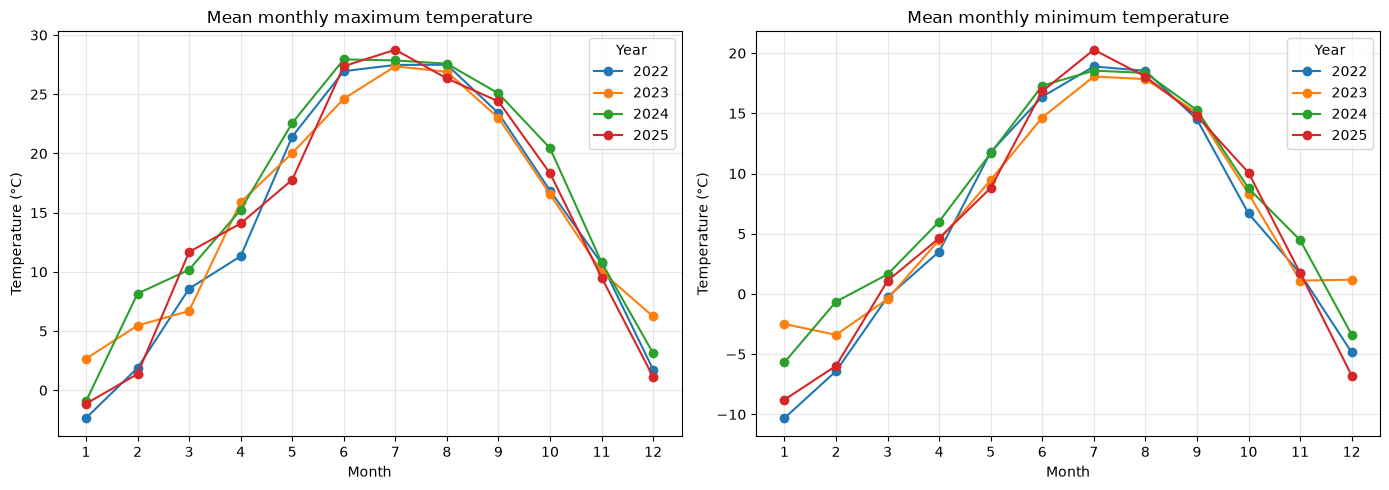

In [203]:
temp_monthly = (
    weather22_25
    .groupby(["year", "month"])
    [["temperature_2m_max", "temperature_2m_min"]]
    .agg(["mean", "std"])
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for year in sorted(weather22_25["year"].unique()):
    data = weather22_25[weather22_25["year"] == year]

    monthly = data.groupby("month").agg(
        max_temp=("temperature_2m_max", "mean"),
        min_temp=("temperature_2m_min", "mean")
    )

    axes[0].plot(monthly.index, monthly["max_temp"],
                 marker="o", label=str(year))
    axes[1].plot(monthly.index, monthly["min_temp"],
                 marker="o", label=str(year))

axes[0].set_title("Mean monthly maximum temperature")
axes[1].set_title("Mean monthly minimum temperature")

for ax in axes:
    ax.set_xlabel("Month")
    ax.set_ylabel("Temperature (°C)")
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=0.3)
    ax.legend(title="Year")

plt.tight_layout()
plt.show()

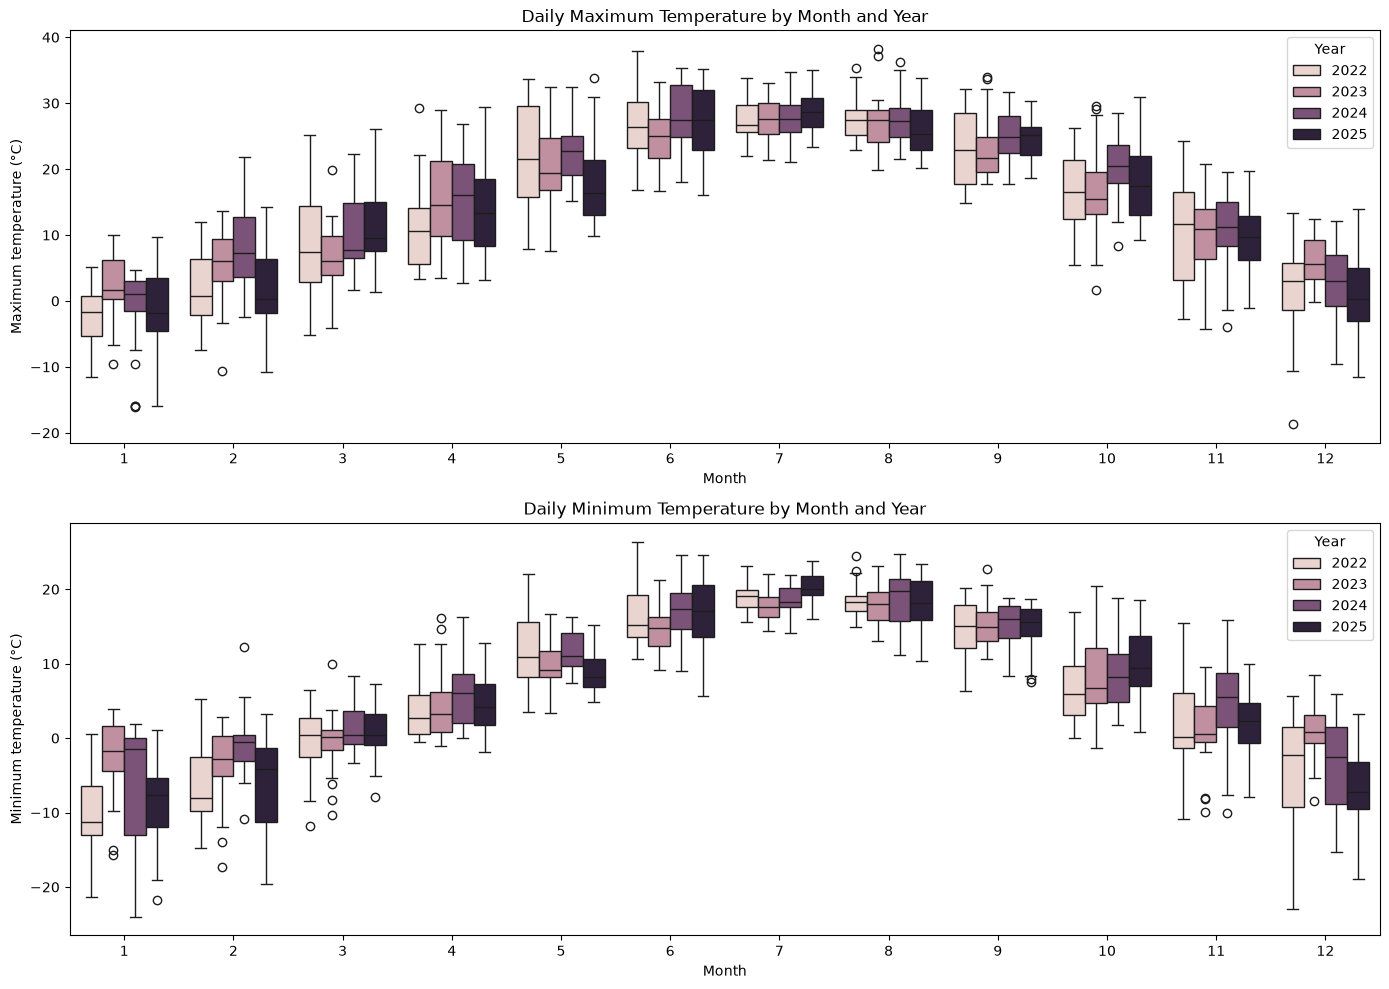

In [204]:
# boxplots max and min temperature by month per year

# Orden de los meses
weather22_25 = weather22_25.sort_values("time")

fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Temperatura máxima
sns.boxplot(
    data=weather22_25,
    x="month",
    y="temperature_2m_max",
    hue="year",
    ax=axes[0]
)
axes[0].set_title("Daily Maximum Temperature by Month and Year")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Maximum temperature (°C)")
axes[0].legend(title="Year")

# Temperatura mínima
sns.boxplot(
    data=weather22_25,
    x="month",
    y="temperature_2m_min",
    hue="year",
    ax=axes[1]
)
axes[1].set_title("Daily Minimum Temperature by Month and Year")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Minimum temperature (°C)")
axes[1].legend(title="Year")

plt.tight_layout()
plt.show()

In [205]:
# Per year (max and min)
weather22_25.groupby("year")[
    ["temperature_2m_max", "temperature_2m_min"]
].agg(["mean", "std", "min", "max"])

temperature_2m_max                        temperature_2m_min             \
                   mean        std   min   max               mean        std   
year                                                                           
2022          14.692055  12.014971 -18.7  37.9           5.913699  10.795908   
2023          15.502740  10.054904 -10.7  38.2           7.055616   8.541988   
2024          16.514481  11.022800 -16.1  36.2           7.709836   9.457322   
2025          15.038082  11.606665 -15.9  35.2           6.295616  10.680033   

                  
       min   max  
year              
2022 -23.0  26.4  
2023 -17.3  23.1  
2024 -24.0  24.7  
2025 -21.8  24.6

### Obtained mean temperature

In [206]:
weather22_25.groupby("year")[["temperature_mean"]].agg(["mean", "std", "min", "max"])

temperature_mean                         
                 mean        std    min    max
year                                          
2022        10.302877  11.238910 -20.85  31.50
2023        11.279178   9.103305 -14.00  30.40
2024        12.112158  10.062301 -20.00  29.85
2025        10.666849  11.002629 -18.85  29.80

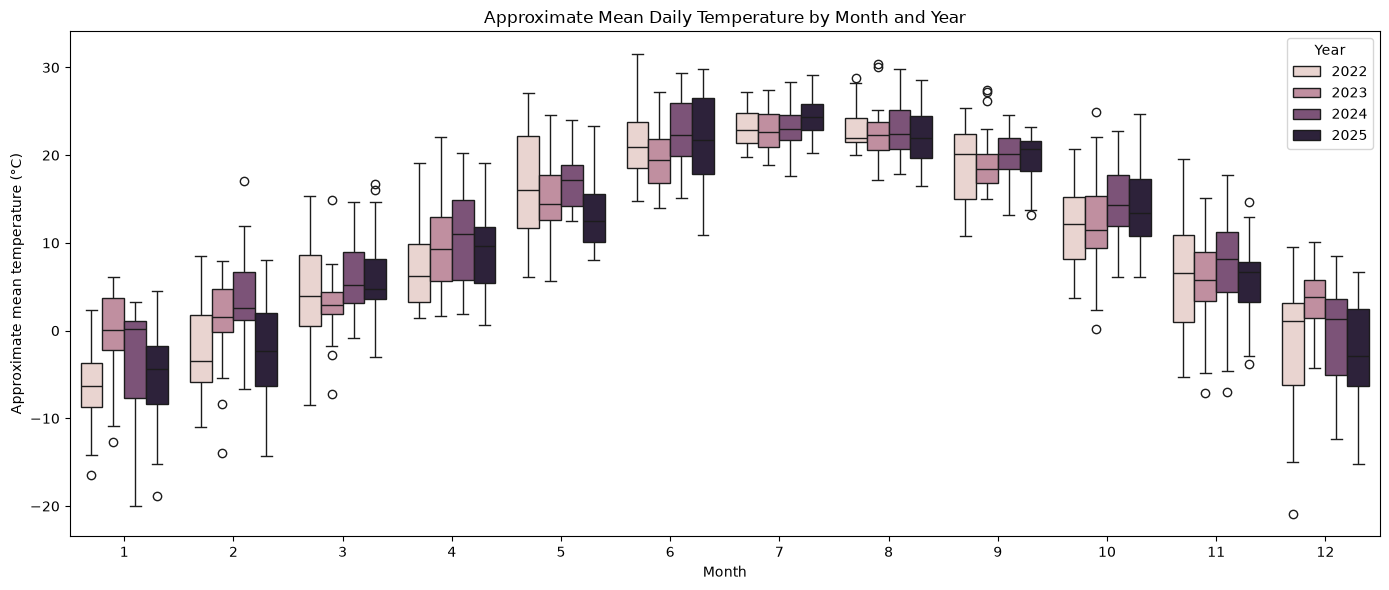

In [208]:
# Boxplot por mes y año
plt.figure(figsize=(14, 6))

sns.boxplot(
    data=weather22_25,
    x="month",
    y="temperature_mean",
    hue="year"
)

plt.title("Approximate Mean Daily Temperature by Month and Year")
plt.xlabel("Month")
plt.ylabel("Approximate mean temperature (°C)")
plt.legend(title="Year")
plt.tight_layout()
plt.show()

### Precipitation and rain

In [215]:
weather22_25

,time,weather_code,temperature_2m_max,temperature_2m_min,sunrise,sunset,rain_sum,snowfall_sum,wind_speed_10m_max,precipitation_sum,daylight_duration,weather,month,year,temperature_mean
0,2022-01-01,75,3.6,-1.9,2022-01-01T08:18,2022-01-01T17:30,3.6,5.32,36.6,11.2,33123.81,Heavy snowfall,1,2022,0.85
1,2022-01-02,75,-1.7,-9.4,2022-01-02T08:18,2022-01-02T17:31,2.6,4.34,34.4,8.8,33170.56,Heavy snowfall,1,2022,-5.55
2,2022-01-03,1,-5.6,-12.7,2022-01-03T08:18,2022-01-03T17:32,0.0,0.00,26.0,0.0,33221.36,Mainly clear,1,2022,-9.15
3,2022-01-04,3,0.1,-6.4,2022-01-04T08:18,2022-01-04T17:33,0.0,0.00,24.6,0.0,33276.72,Overcast,1,2022,-3.15
4,2022-01-05,3,0.0,-12.8,2022-01-05T08:18,2022-01-05T17:34,0.0,0.00,44.8,0.0,33336.53,Overcast,1,2022,-6.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1456,2025-12-27,3,5.2,3.0,2025-12-27T08:17,2025-12-27T17:26,0.0,0.00,15.5,0.0,32948.73,Overcast,12,2025,4.10
1457,2025-12-28,63,14.0,-3.0,2025-12-28T08:17,2025-12-28T17:27,28.5,0.00,36.5,28.5,32975.78,Moderate rain,12,2025,5.50
1458,2025-12-29,73,-3.0,-9.8,2025-12-29T08:17,2025-12-29T17:28,0.4,0.84,39.4,1.6,33006.84,Moderate snowfall,12,2025,-6.40
1459,2025-12-30,73,-4.6,-11.6,2025-12-30T08:18,2025-12-30T17:28,0.4,0.70,17.1,1.4,33041.90,Moderate snowfall,12,2025,-8.10


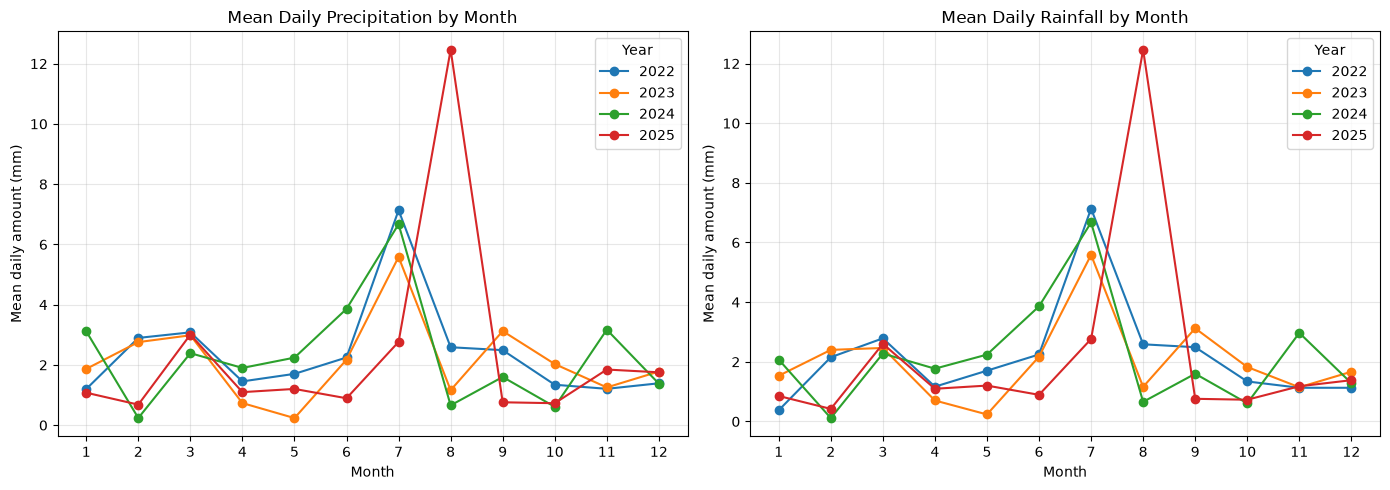

In [214]:
# Asegurarnos de que month y year sean numéricos
#weather22_25["month"] = weather22_25["month"].astype(int)
#weather22_25["year"] = weather22_25["year"].astype(int)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for year in sorted(weather22_25["year"].unique()):
    data = weather22_25[weather22_25["year"] == year]

    monthly = data.groupby("month").agg(
        precipitation=("precipitation_sum", "mean"),
        rain=("rain_sum", "mean")
    )

    axes[0].plot(
        monthly.index, monthly["precipitation"],
        marker="o", label=str(year)
    )
    axes[1].plot(
        monthly.index, monthly["rain"],
        marker="o", label=str(year)
    )

axes[0].set_title("Mean Daily Precipitation by Month")
axes[1].set_title("Mean Daily Rainfall by Month")

for ax in axes:
    ax.set_xlabel("Month")
    ax.set_ylabel("Mean daily amount (mm)")
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=0.3)
    ax.legend(title="Year")

plt.tight_layout()
plt.show()

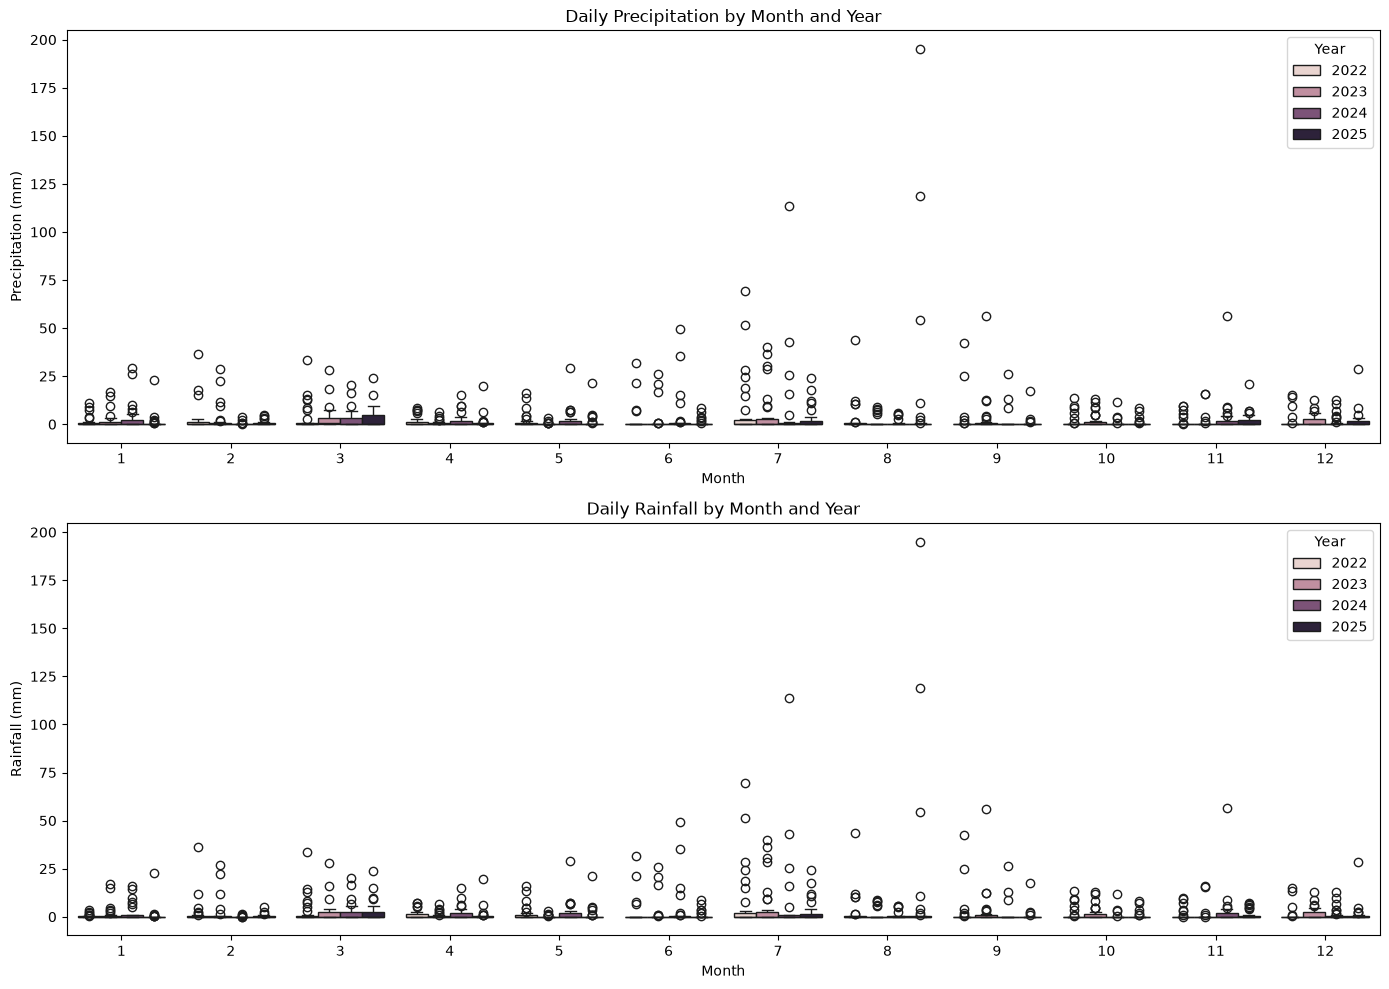

In [210]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))

# Precipitación total diaria
sns.boxplot(
    data=weather22_25,
    x="month",
    y="precipitation_sum",
    hue="year",
    ax=axes[0]
)
axes[0].set_title("Daily Precipitation by Month and Year")
axes[0].set_xlabel("Month")
axes[0].set_ylabel("Precipitation (mm)")
axes[0].legend(title="Year")

# Lluvia total diaria
sns.boxplot(
    data=weather22_25,
    x="month",
    y="rain_sum",
    hue="year",
    ax=axes[1]
)
axes[1].set_title("Daily Rainfall by Month and Year")
axes[1].set_xlabel("Month")
axes[1].set_ylabel("Rainfall (mm)")
axes[1].legend(title="Year")

plt.tight_layout()
plt.show()

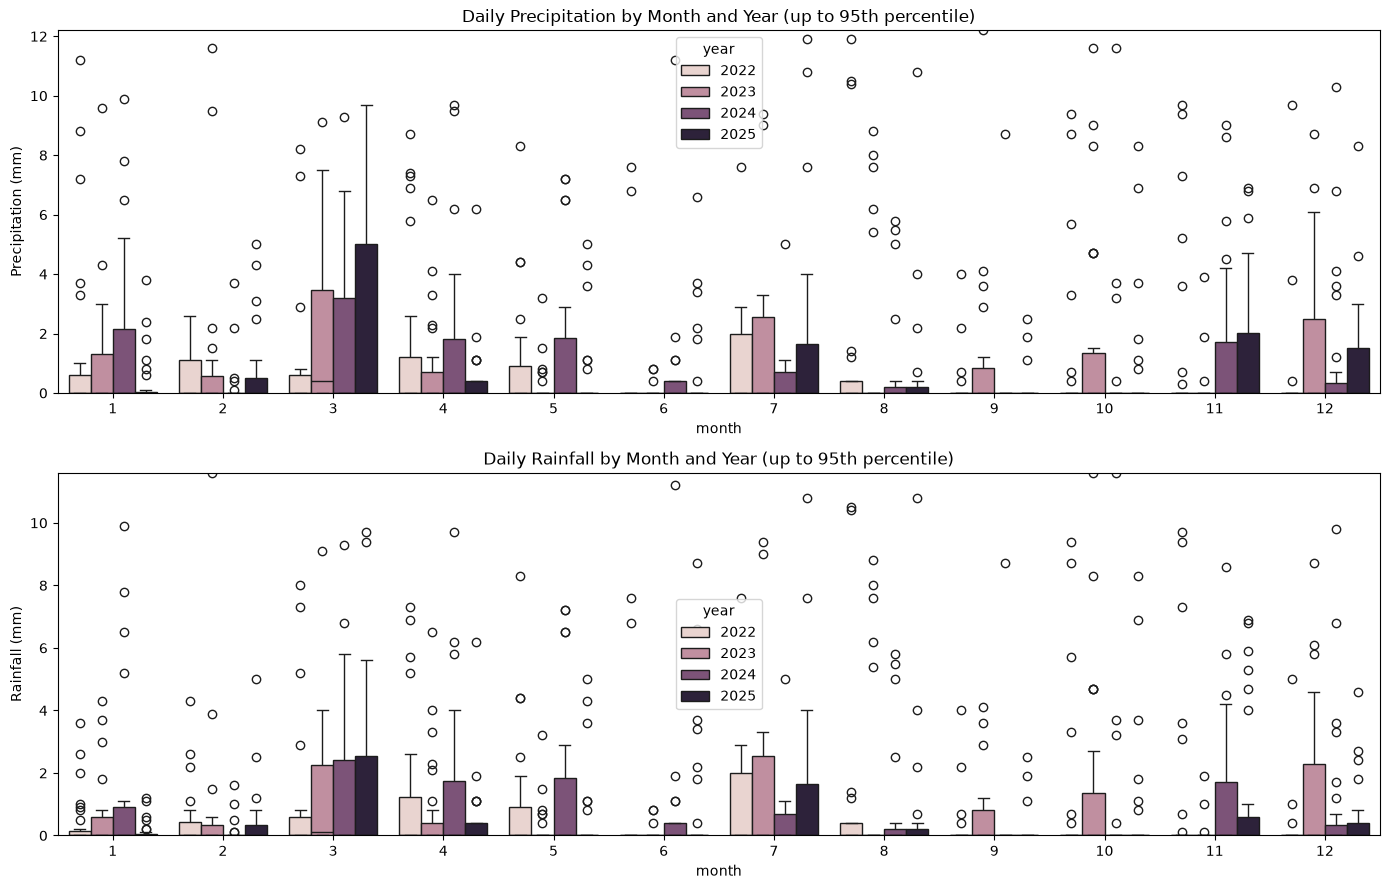

In [211]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

sns.boxplot(
    data=weather22_25,
    x="month",
    y="precipitation_sum",
    hue="year",
    ax=axes[0]
)
axes[0].set_ylim(0, weather22_25["precipitation_sum"].quantile(0.95))
axes[0].set_title("Daily Precipitation by Month and Year (up to 95th percentile)")
axes[0].set_ylabel("Precipitation (mm)")

sns.boxplot(
    data=weather22_25,
    x="month",
    y="rain_sum",
    hue="year",
    ax=axes[1]
)
axes[1].set_ylim(0, weather22_25["rain_sum"].quantile(0.95))
axes[1].set_title("Daily Rainfall by Month and Year (up to 95th percentile)")
axes[1].set_ylabel("Rainfall (mm)")

plt.tight_layout()
plt.show()

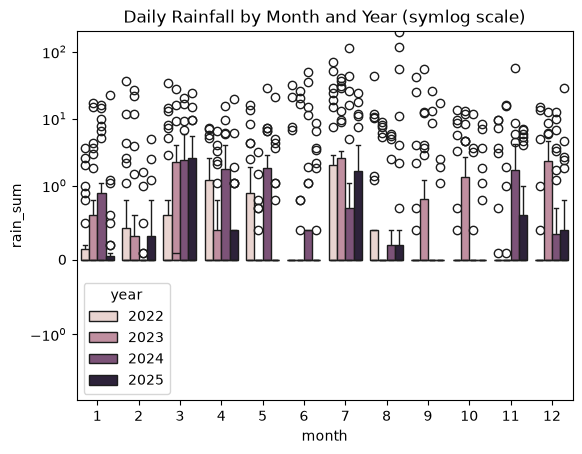

In [212]:
ax = sns.boxplot(
    data=weather22_25,
    x="month",
    y="rain_sum",
    hue="year"
)

ax.set_yscale("symlog", linthresh=1)
ax.set_title("Daily Rainfall by Month and Year (symlog scale)")
plt.show()

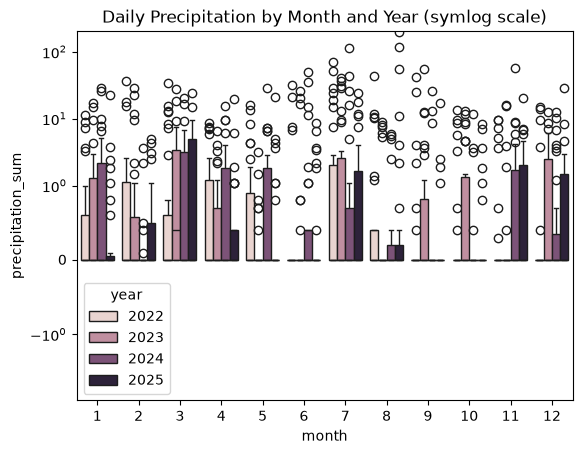

In [213]:
ax = sns.boxplot(
    data=weather22_25,
    x="month",
    y="precipitation_sum",
    hue="year"
)

ax.set_yscale("symlog", linthresh=1)
ax.set_title("Daily Precipitation by Month and Year (symlog scale)")
plt.show()

Precipitation and rain may explain a decrease in number of trips during 
2023, 2024, 2022 - Might also be a good predictor for these months

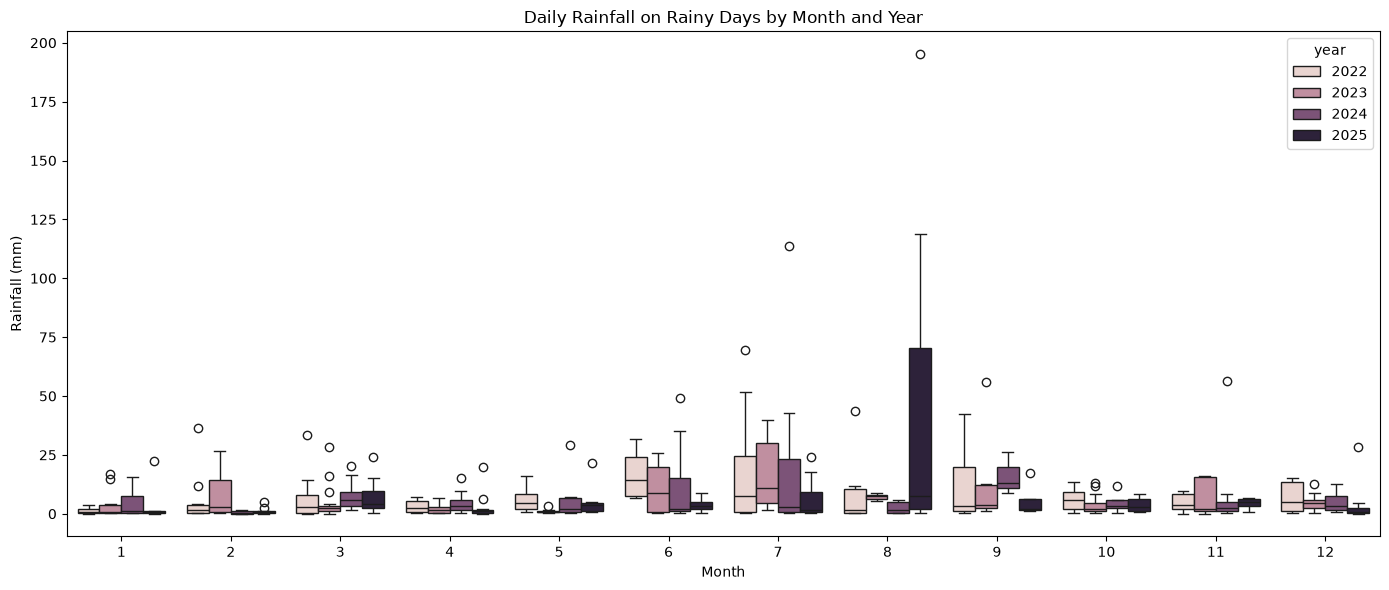

In [175]:
# Separate rainy from non-rainy days
rainy_days = weather22_25[
    weather22_25["rain_sum"] > 0
]

plt.figure(figsize=(14, 6))

sns.boxplot(
    data=rainy_days,
    x="month",
    y="rain_sum",
    hue="year"
)

plt.title("Daily Rainfall on Rainy Days by Month and Year")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")
plt.tight_layout()
plt.show()

In [ ]:
# August 2025 had days with extreme rain

### Snow and wind

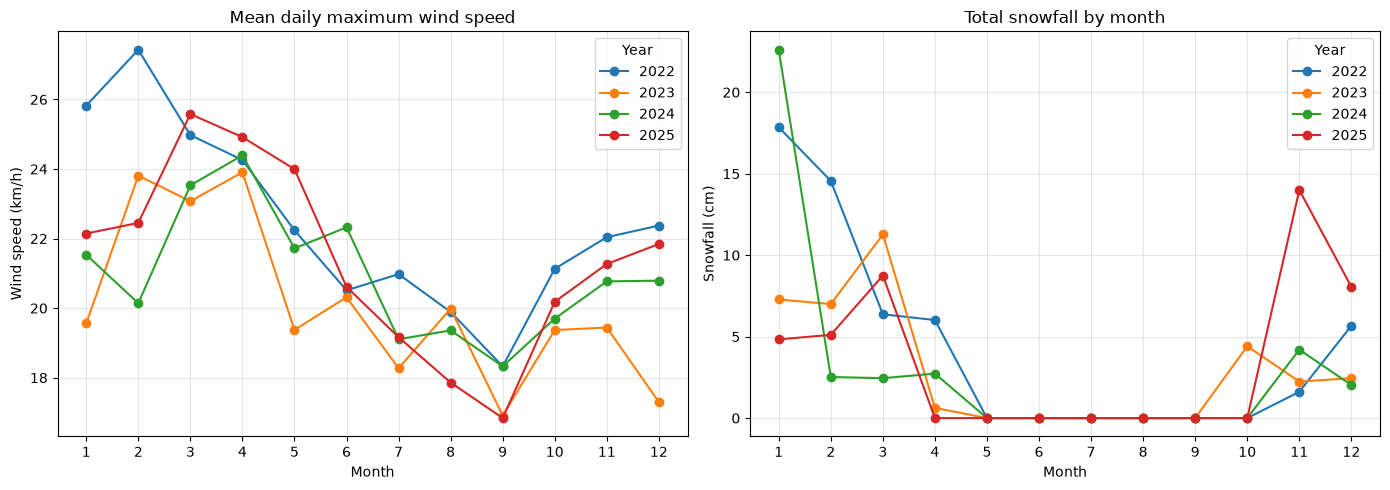

In [216]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for year in sorted(weather22_25["year"].unique()):
    data = weather22_25[weather22_25["year"] == year]

    monthly = data.groupby("month").agg(
        wind=("wind_speed_10m_max", "mean"),
        snow=("snowfall_sum", "sum")
    )

    axes[0].plot(monthly.index, monthly["wind"],
                 marker="o", label=str(year))
    axes[1].plot(monthly.index, monthly["snow"],
                 marker="o", label=str(year))

axes[0].set_title("Mean daily maximum wind speed")
axes[1].set_title("Total snowfall by month")

axes[0].set_ylabel("Wind speed (km/h)")  
axes[1].set_ylabel("Snowfall (cm)")

for ax in axes:
    ax.set_xlabel("Month")
    ax.set_xticks(range(1, 13))
    ax.grid(alpha=0.3)
    ax.legend(title="Year")

plt.tight_layout()
plt.show()

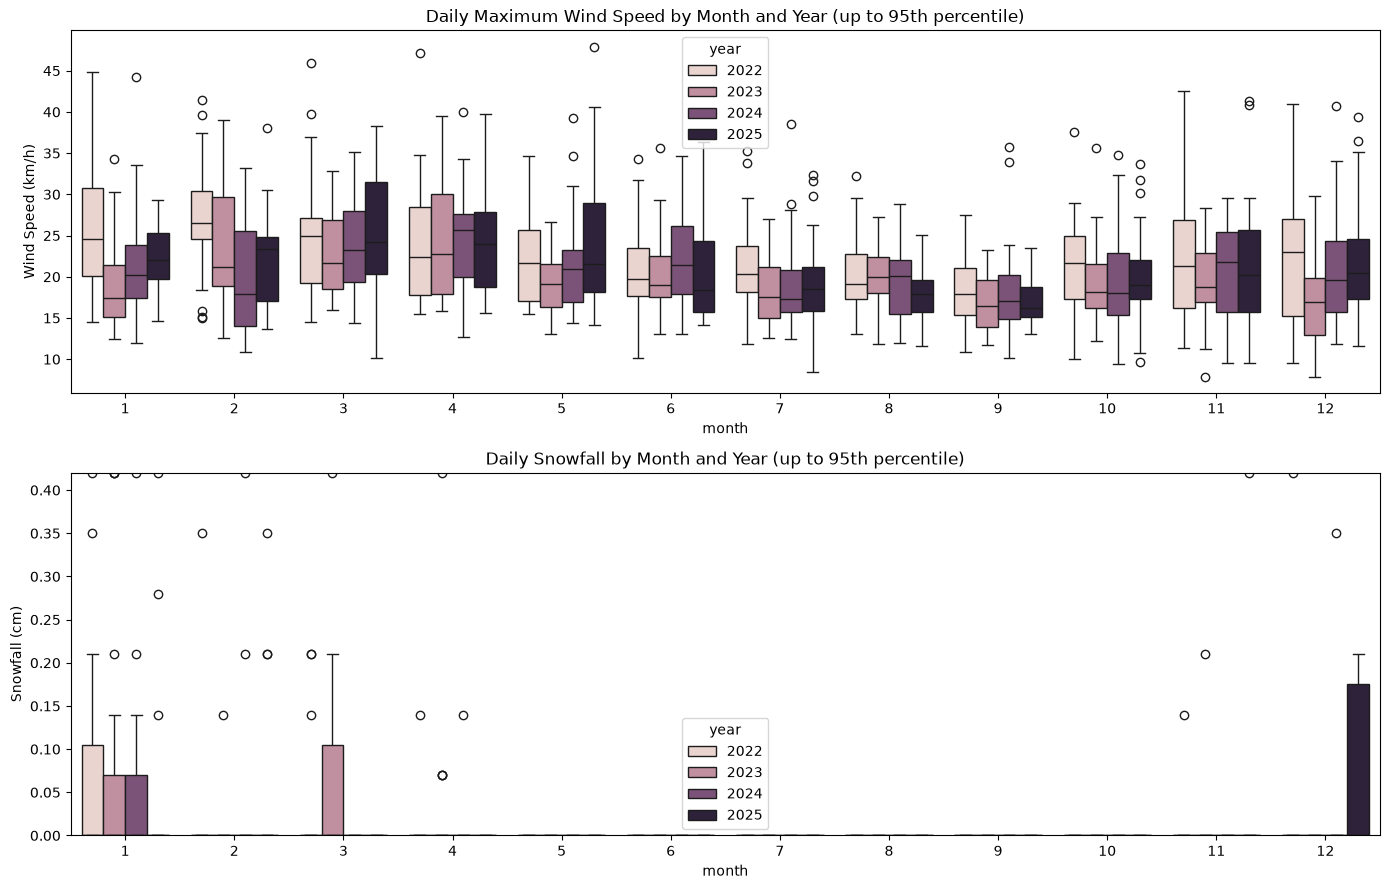

In [217]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

sns.boxplot(
    data=weather22_25,
    x="month",
    y="wind_speed_10m_max",
    hue="year",
    ax=axes[0]
)
#axes[0].set_ylim(0, weather22_25["wind_speed_10m_max"].quantile(0.95))
axes[0].set_title("Daily Maximum Wind Speed by Month and Year (up to 95th percentile)")
axes[0].set_ylabel("Wind Speed (km/h)")

sns.boxplot(
    data=weather22_25,
    x="month",
    y="snowfall_sum",
    hue="year",
    ax=axes[1]
)
axes[1].set_ylim(0, weather22_25["snowfall_sum"].quantile(0.95))
axes[1].set_title("Daily Snowfall by Month and Year (up to 95th percentile)")
axes[1].set_ylabel("Snowfall (cm)")

plt.tight_layout()
plt.show()

Tolerable wind speed: (what I consider tolerable to ride): 10 a 28 km/h (maybe)

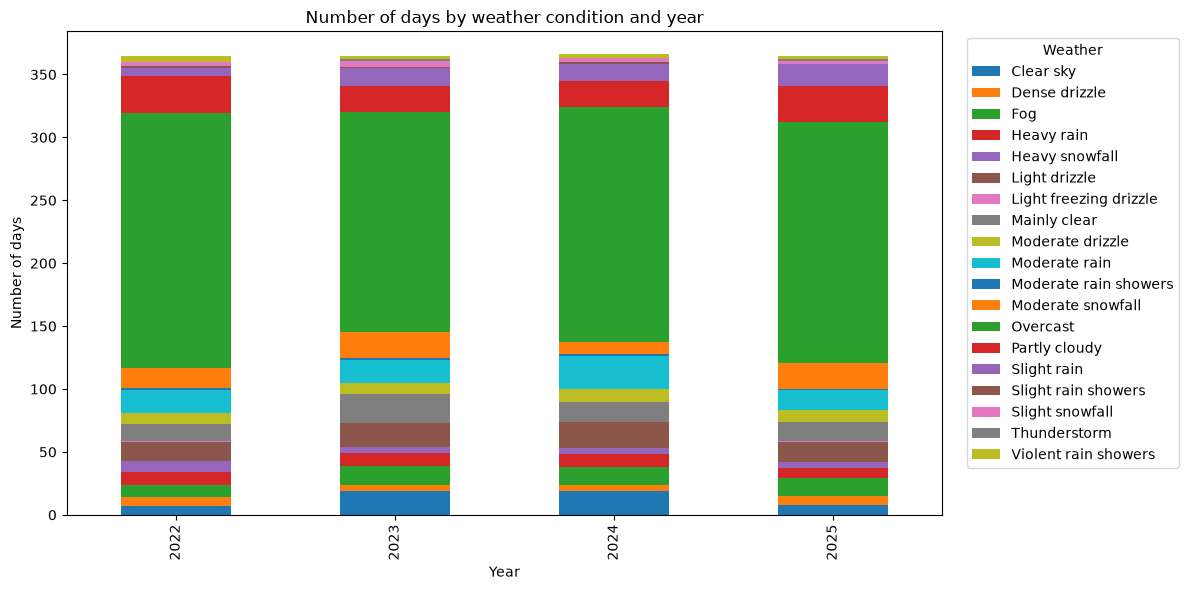

In [218]:
weather_counts = pd.crosstab(
    weather22_25["year"],
    weather22_25["weather"]
)

weather_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6)
)

plt.title("Number of days by weather condition and year")
plt.xlabel("Year")
plt.ylabel("Number of days")
plt.legend(title="Weather", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

##### Idea!
How informative would it be to assign certain days an special label of "extreme weather" using the labels given in the dataset.
I propose using these evets as days with extreme weather (special event):
Potentially add an extra label "extreme weather" (0,1) boolean.
- Thunderstorm 
- Violent rain showers 
- Heavy rain 
- Heavy snowfall 

Of course one limitation is that we don't know when during the day this event happened, could have been during the day or night. 

In [219]:
weather_year_month = weather22_25.groupby("year")[["month","weather"]]

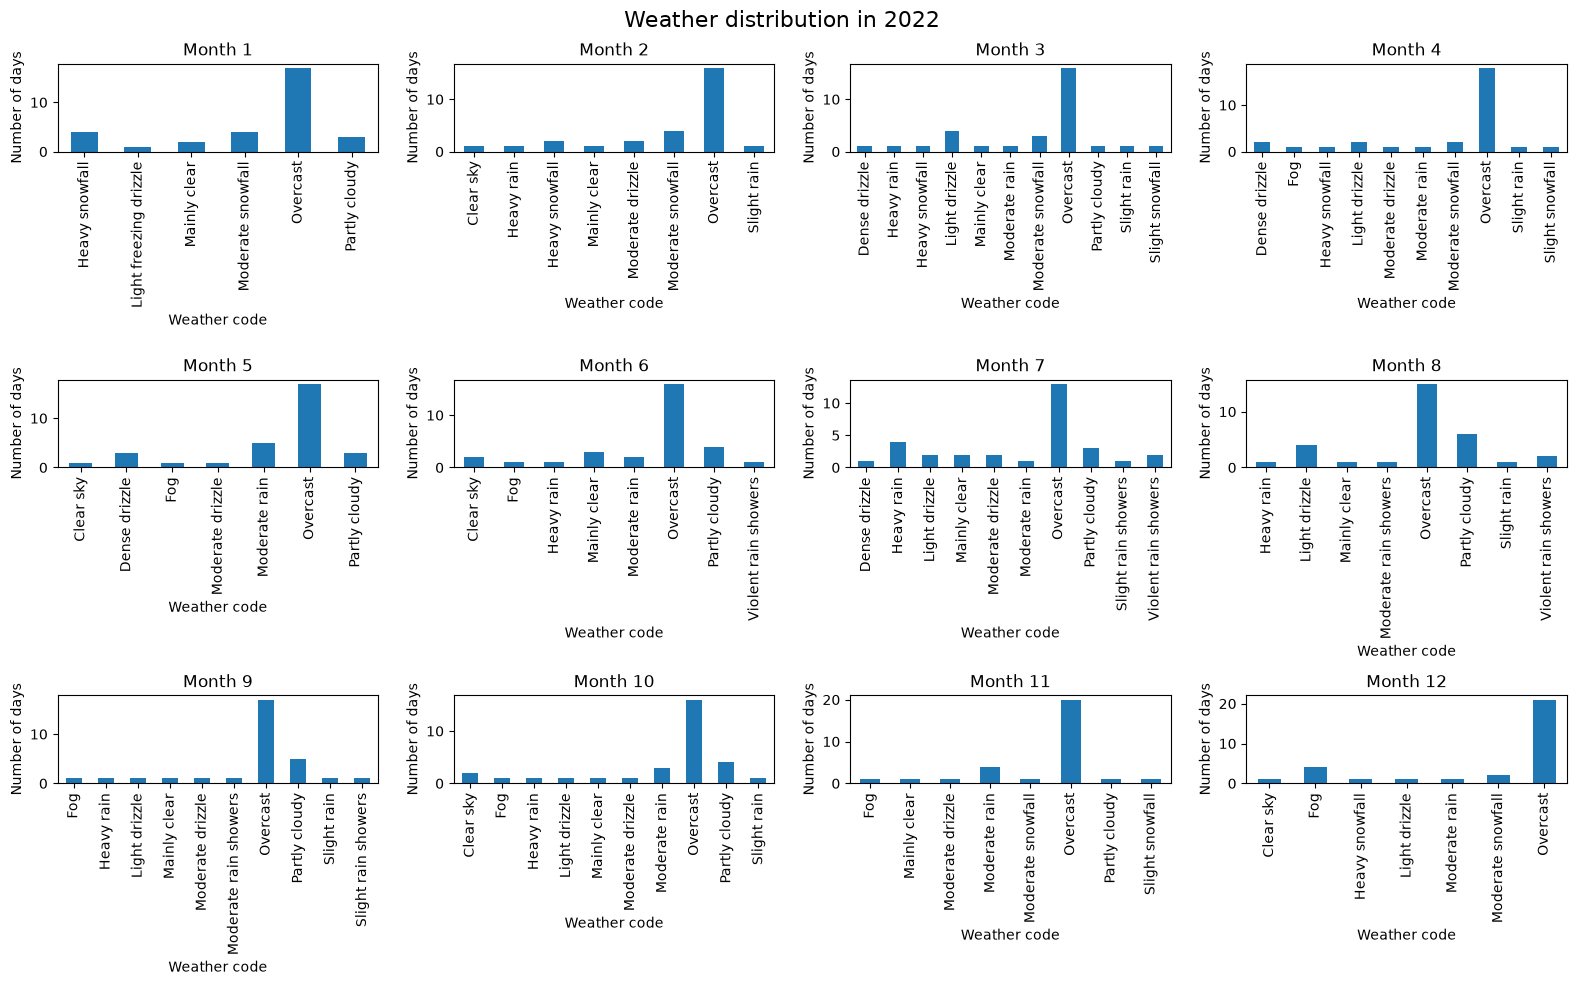

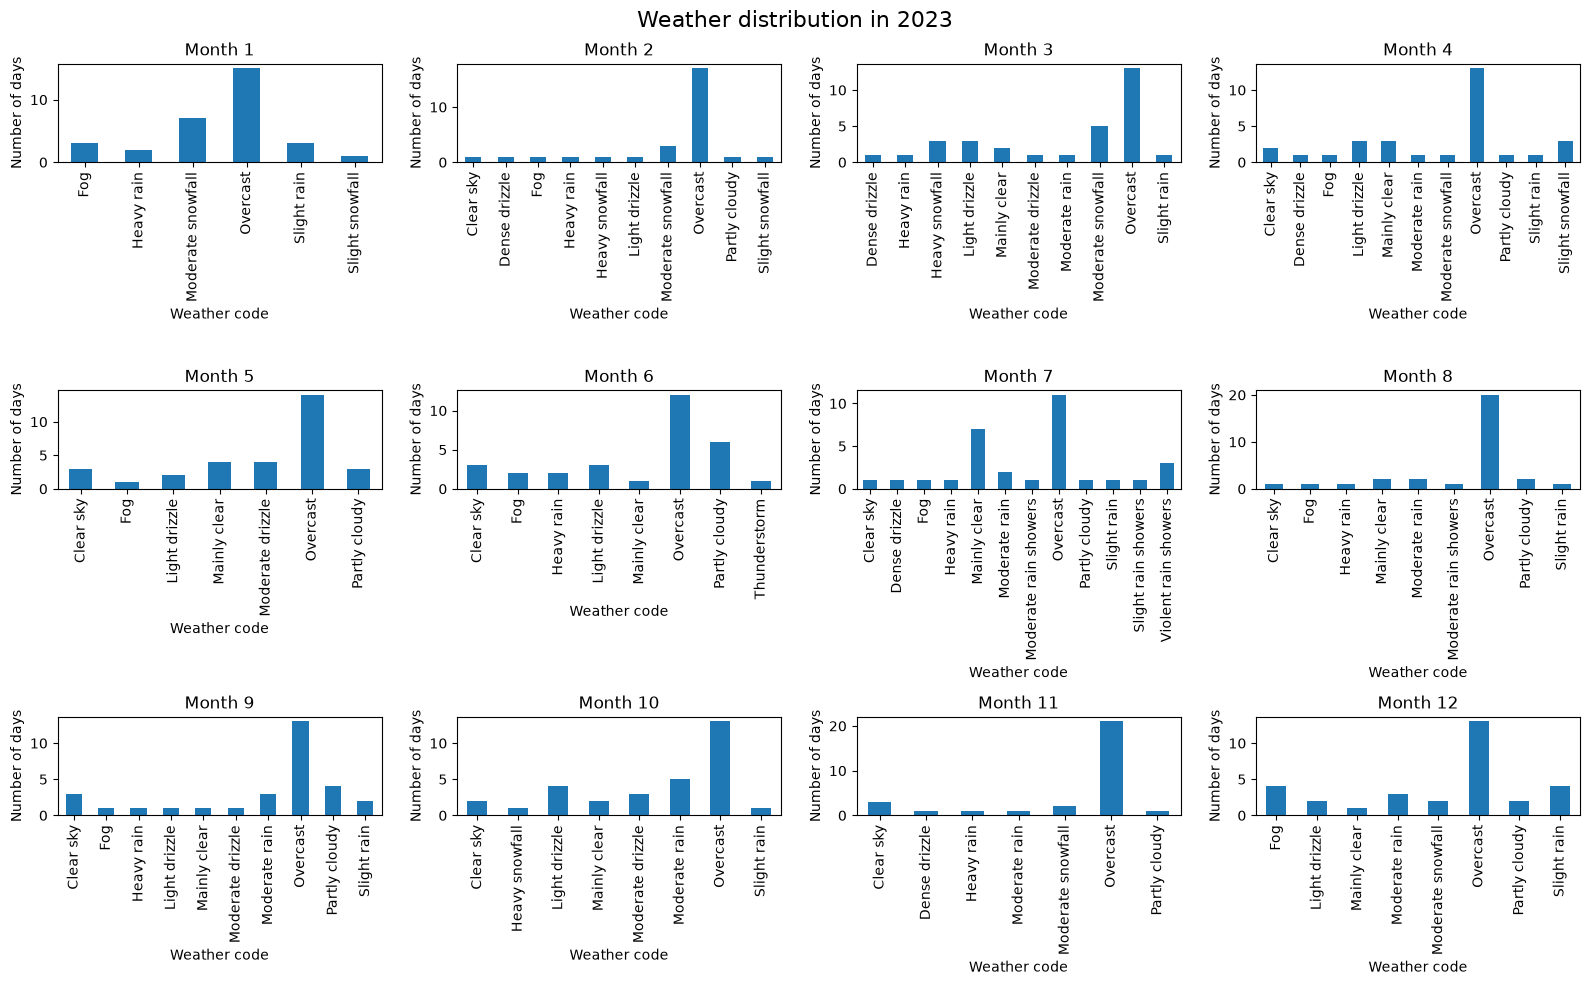

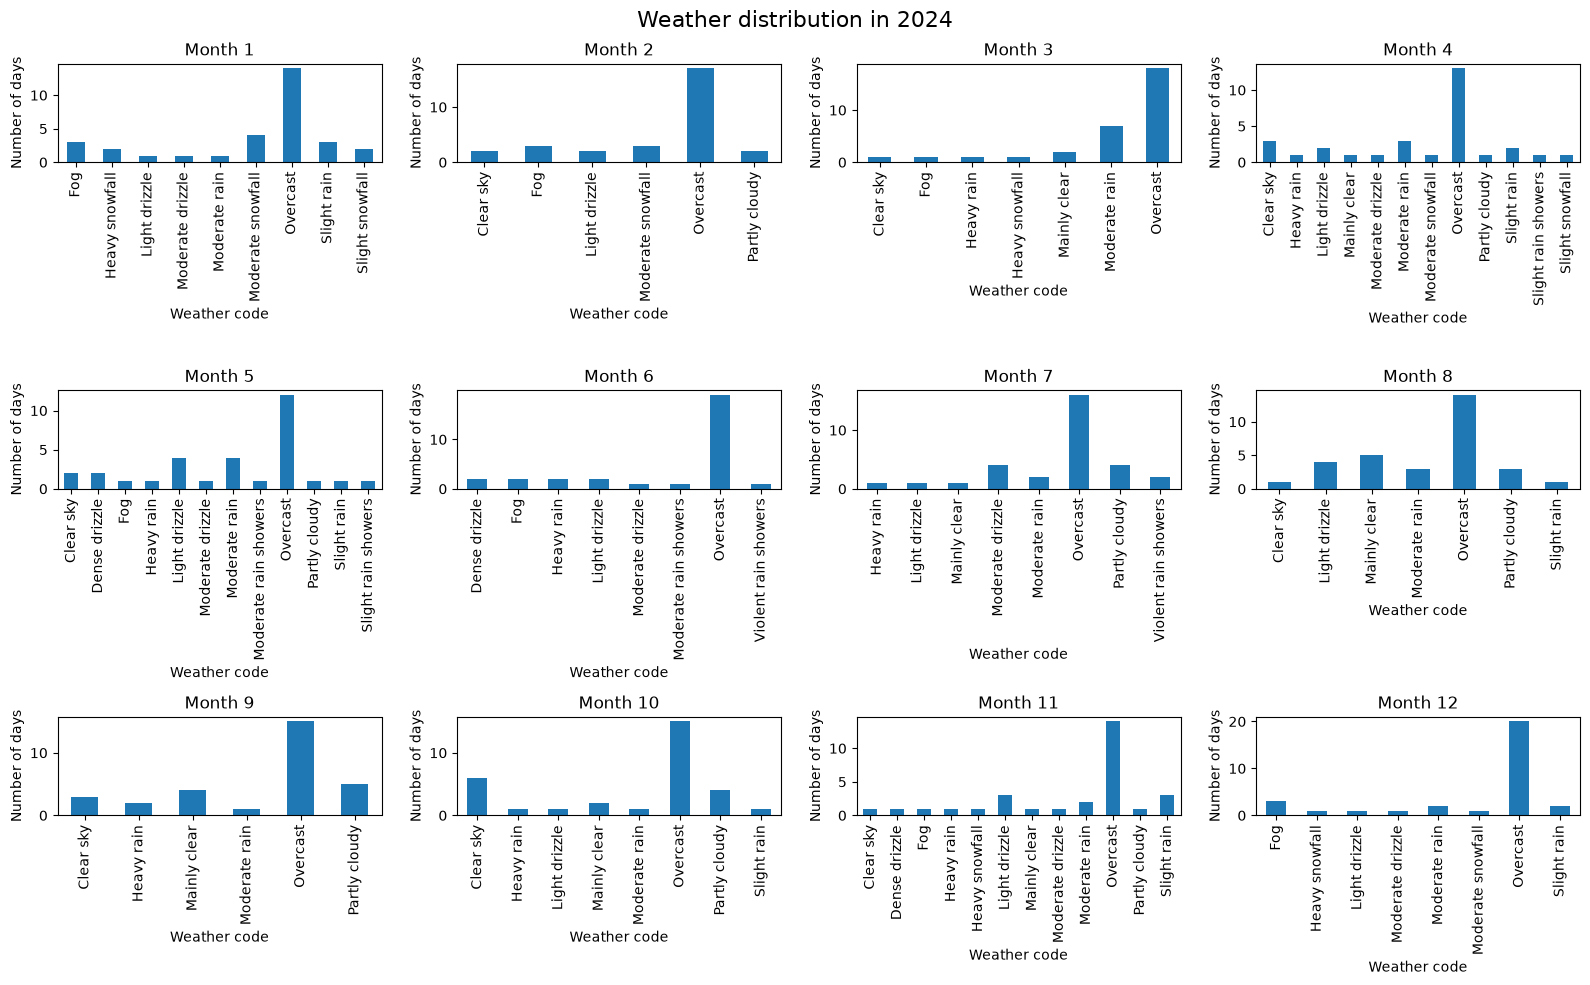

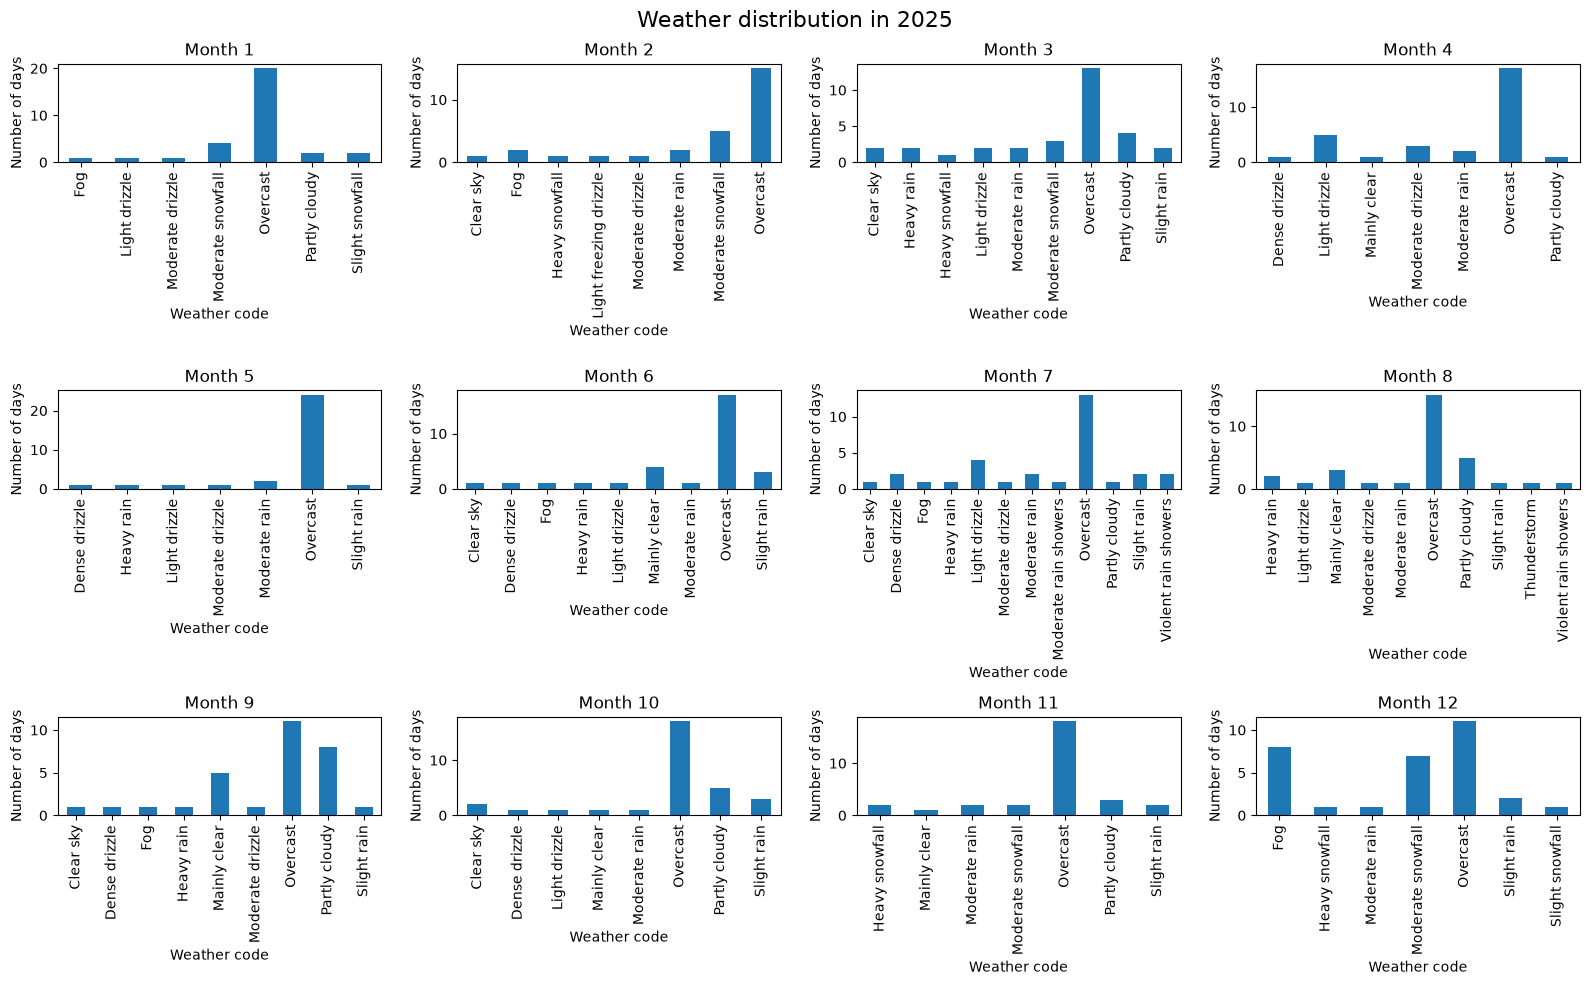

In [114]:
import matplotlib.pyplot as plt

for year in sorted(weather22_25["year"].unique()):
    fig, axes = plt.subplots(3, 4, figsize=(16, 10))
    axes = axes.flatten()

    df_year = weather22_25[weather22_25["year"] == year]

    for month in range(1, 13):
        ax = axes[month - 1]
        df_month = df_year[df_year["month"] == month]

        df_month["weather"].value_counts().sort_index().plot(
            kind="bar",
            ax=ax
        )

        ax.set_title(f"Month {month}")
        ax.set_xlabel("Weather code")
        ax.set_ylabel("Number of days")
        ax.tick_params(axis="x", rotation=90)

    fig.suptitle(f"Weather distribution in {year}", fontsize=16)
    plt.tight_layout()
    plt.show()

### What could we do with this data?
- Since we aim to use bike-share data as a *social sensor*, meteorological events can be incorporated as external events that may disrupt or influence mobility patterns across the city.
- Weather conditions may be important predictors of bike-share usage. Therefore, incorporating meteorological variables into the dataset is essential to assess their contribution to explaining changes in cycling patterns. To quantify their effects and distinguish them from other factors, we should integrate the weather and bike-share data and develop a predictive model.
- Do we want to save: sunrise (iso8601), sunset (iso8601) or daylight_duration (s) ? Maybe, if this can allow us to explain late trips during days with more daylight duration as in summer, having trips at night is not as rare in summer as it is in december. 

# Integration with the dataset

In [ ]:
# Reading files
save_folder = './clean/'
weather22_25 = pd.read_csv(save_folder + 'weather_2022_2025.csv')